# 02 · Baseline and regression

**Question:** what explains a treaty-year's loss ratio, and by how much?

Three parts, in this order:
1. **Baseline.** Predict every loss ratio as the portfolio average. Everything else is judged against it.
2. **Regression.** Ordinary least squares with statsmodels, interpreted coefficient by coefficient.
3. **Assumption checks.** Residuals, normality, multicollinearity, influence, each with a verdict.

Reads `data/treaty_year_clean.csv`, written by notebook 01. *Synthetic data; no client data used.*

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import variance_inflation_factor

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
CLEAN = ROOT / "data" / "treaty_year_clean.csv"
FIG = ROOT / "outputs" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
if not CLEAN.exists():
    raise FileNotFoundError("Run notebooks/01_eda.ipynb first: it writes data/treaty_year_clean.csv")

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

def save_fig(name):
    plt.tight_layout()
    plt.savefig(FIG / f"{name}.png", dpi=150)
    plt.show()

df = pd.read_csv(CLEAN)
df["log_policies"] = np.log(df.policies_in_force)   # spans 500 to 50,000: two orders of magnitude
print(df.shape)

(1163, 21)


### Train / test split

80% to fit, 20% held back to check the model on data it has not seen. A **random** split (fixed seed) is right here
because the goal is to *explain* what drives loss ratios across the book, not to forecast next year. A forecasting model
would need a time-based split (train on earlier years, test on later ones) so it never sees the future.

In [2]:
train, test = train_test_split(df, test_size=0.2, random_state=42)
print(f"train {len(train)} rows, test {len(test)} rows")

train 930 rows, test 233 rows


## Part 1 · Baseline: predict the average

Every treaty-year is predicted to have the training set's average loss ratio. No model, no features.

In [3]:
baseline_value = train.loss_ratio.mean()
baseline_pred = np.full(len(test), baseline_value)

baseline_rmse = np.sqrt(mean_squared_error(test.loss_ratio, baseline_pred))
baseline_r2 = r2_score(test.loss_ratio, baseline_pred)
print(f"Baseline prediction: {baseline_value:.3f} for every treaty-year")
print(f"Test RMSE {baseline_rmse:.3f} | Test R² {baseline_r2:.3f}")

Baseline prediction: 0.760 for every treaty-year
Test RMSE 0.231 | Test R² -0.005


The baseline is wrong by about **0.23 of loss ratio** on a typical treaty-year, and its R² is essentially zero (slightly
below, because the training average is not exactly the test average). That is the bar the regression has to clear.

## Part 2 · The regression

Features follow the hypotheses from notebook 01. Each categorical variable needs one **reference level** that the others
are compared with; without dropping one, the dummies plus the intercept are perfectly collinear and the model cannot fit.

| Variable | Reference level (the comparison point) |
|---|---|
| line_of_business | **Death** (the profitable benchmark) |
| treaty_type | **Quota Share** (the simplest structure) |
| region | **NSW** |

Only **one** size measure goes in, log(policies in force): premium, claim count and expenses all measure size too and are
correlated with it at 0.7-0.97 (Figure 7), so adding them would create multicollinearity.

In [4]:
formula = (
    "loss_ratio ~ C(line_of_business, Treatment('Death'))"
    " + treaty_age"
    " + large_claim_count"
    " + log_policies"
    " + C(treaty_type, Treatment('Quota Share'))"
    " + cession_pct"
    " + C(region, Treatment('NSW'))"
)
model = smf.ols(formula, data=train).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:             loss_ratio   R-squared:                       0.326
Model:                            OLS   Adj. R-squared:                  0.316
Method:                 Least Squares   F-statistic:                     34.08
Date:                Mon, 12 Oct 2026   Prob (F-statistic):           1.11e-69
Time:                        20:35:04   Log-Likelihood:                 196.58
No. Observations:                 930   AIC:                            -365.2
Df Residuals:                     916   BIC:                            -297.5
Df Model:                          13                                         
Covariance Type:            nonrobust                                         
                                                                   coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------

In [5]:
# A tidier version of the coefficient table for the report
def short(name):
    return (name.replace("C(line_of_business, Treatment('Death'))[T.", "Line: ")
                .replace("C(treaty_type, Treatment('Quota Share'))[T.", "Type: ")
                .replace("C(region, Treatment('NSW'))[T.", "Region: ").replace("]", ""))

ci = model.conf_int()
coef_table = pd.DataFrame({
    "coefficient": model.params, "ci_low": ci[0], "ci_high": ci[1], "p_value": model.pvalues,
}).drop(index="Intercept")
coef_table.index = coef_table.index.map(short)
coef_table["significant (p<0.05)"] = np.where(coef_table.p_value < 0.05, "yes", "no")
coef_table.sort_values("coefficient", ascending=False)

,coefficient,ci_low,ci_high,p_value,significant (p<0.05)
Line: Income Protection,0.2631,0.2280,0.2982,0.0000,yes
Line: Trauma,0.1742,0.1394,0.2091,0.0000,yes
large_claim_count,0.1274,0.1072,0.1476,0.0000,yes
Line: TPD,0.1061,0.0673,0.1449,0.0000,yes
Type: Excess of Loss,0.0681,0.0319,0.1044,0.0002,yes
Type: Surplus,0.0540,0.0240,0.0840,0.0004,yes
treaty_age,0.0170,0.0125,0.0214,0.0000,yes
Region: WA,0.0153,-0.0232,0.0537,0.4353,no
Region: SA,0.0098,-0.0318,0.0514,0.6437,no
log_policies,0.0073,-0.0036,0.0181,0.1892,no


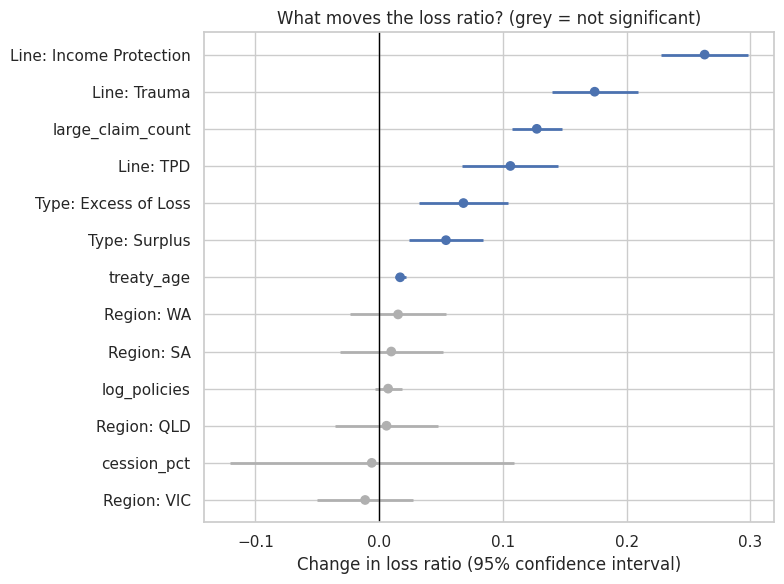

In [6]:
# Coefficient plot: every effect with its 95% confidence interval
plot = coef_table.sort_values("coefficient")
fig, ax = plt.subplots(figsize=(8, 6))
colours = np.where(plot.p_value < 0.05, "#4C72B0", "#B0B0B0")
ax.errorbar(plot.coefficient, plot.index, xerr=[plot.coefficient - plot.ci_low, plot.ci_high - plot.coefficient],
            fmt="none", ecolor=colours, elinewidth=2)
ax.scatter(plot.coefficient, plot.index, c=colours, zorder=3)
ax.axvline(0, color="black", linewidth=1)
ax.set(xlabel="Change in loss ratio (95% confidence interval)",
       title="What moves the loss ratio? (grey = not significant)")
save_fig("08_coefficients")

### Reading the coefficients

Each coefficient is the change in loss ratio for that feature, **holding everything else in the model constant**.

**Line of business (vs Death): the main finding.**
- An **Income Protection** treaty runs a loss ratio about **0.26 higher** than an otherwise identical Death treaty
  (95% CI roughly 0.23 to 0.30, p < 0.001). On a $10m premium that is about $2.6m more in claims a year.
- **Trauma** runs about **0.17 higher** and **TPD** about **0.11 higher**, both highly significant.

**Treaty age.** A treaty **one year older** runs a loss ratio about **0.017 higher**, all else equal (p < 0.001). Ten years
of ageing adds about 0.17, the same size as the gap between Death and Trauma. Consistent with anti-selection.

**Large claims.** Each claim above the retention limit adds about **0.13** to that year's ratio (p < 0.001). Two in a year
add about a quarter, enough to tip a typical treaty from profit into loss.

**Treaty type (vs Quota Share).** Excess of Loss runs about **0.07 higher** and Surplus about **0.05 higher**; both are
significant but much smaller than the line-of-business effects.

**Size, log(policies in force).** Small and **not significant** (p ≈ 0.19). Doubling a treaty's size changes its expected
loss ratio by about 0.005. As notebook 01 suggested, size affects how much a treaty *swings*, not where it *centres*.

**cession_pct: not significant, and that is the right answer** (coefficient ≈ 0, p ≈ 0.92). The reinsurer's share scales
premium and claims by the same factor, so it cancels out of the ratio. A model that found it significant would be
picking up noise.

**Region: not significant** (every p > 0.4). Where the cedent is based does not change the loss ratio once line, age and
claims are accounted for.

### How well does it do on the held-back 20%?

In [7]:
test_pred = model.predict(test)
model_rmse = np.sqrt(mean_squared_error(test.loss_ratio, test_pred))
model_r2 = r2_score(test.loss_ratio, test_pred)

comparison = pd.DataFrame({
    "Test RMSE": [baseline_rmse, model_rmse],
    "Test R²": [baseline_r2, model_r2],
}, index=["Baseline (predict the average)", "OLS regression"])
display(comparison)
print(f"Training R² {model.rsquared:.3f} (adjusted {model.rsquared_adj:.3f}) vs test R² {model_r2:.3f}: "
      "similar, so the model is not overfitting.")
print(f"RMSE improvement over the baseline: {1 - model_rmse / baseline_rmse:.1%}")

,Test RMSE,Test R²
Baseline (predict the average),0.2315,-0.0053
OLS regression,0.1923,0.3061


Training R² 0.326 (adjusted 0.316) vs test R² 0.306: similar, so the model is not overfitting.
RMSE improvement over the baseline: 16.9%


## Part 3 · Assumption checks

OLS gives trustworthy standard errors and p-values only if its assumptions roughly hold. Four checks, each with a verdict.

### Check 1 · Residuals against fitted values (constant variance)

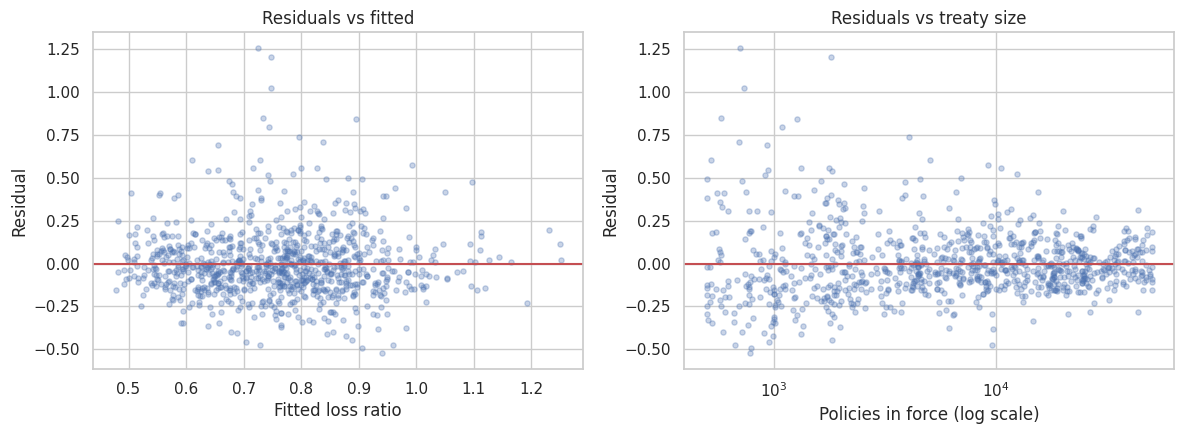

Breusch-Pagan test for constant variance: p = 1.4e-12


In [8]:
resid = model.resid
fitted = model.fittedvalues

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].scatter(fitted, resid, alpha=0.3, s=14)
axes[0].axhline(0, color="#C44E52")
axes[0].set(xlabel="Fitted loss ratio", ylabel="Residual", title="Residuals vs fitted")
axes[1].scatter(train.policies_in_force, resid, alpha=0.3, s=14)
axes[1].set_xscale("log")
axes[1].axhline(0, color="#C44E52")
axes[1].set(xlabel="Policies in force (log scale)", ylabel="Residual", title="Residuals vs treaty size")
save_fig("09_residuals")

bp_stat, bp_p, _, _ = het_breuschpagan(resid, model.model.exog)
print(f"Breusch-Pagan test for constant variance: p = {bp_p:.2g}")

In [9]:
# Remedy: heteroscedasticity-robust (HC3) standard errors. Same coefficients, honest p-values.
robust = smf.ols(formula, data=train).fit(cov_type="HC3")
compare_p = pd.DataFrame({"p (ordinary)": model.pvalues, "p (robust HC3)": robust.pvalues}).drop(index="Intercept")
compare_p.index = compare_p.index.map(short)
compare_p["same verdict at 5%?"] = np.where((compare_p.iloc[:, 0] < 0.05) == (compare_p.iloc[:, 1] < 0.05), "yes", "NO")
compare_p

,p (ordinary),p (robust HC3),same verdict at 5%?
Line: Income Protection,0.0000,0.0000,yes
Line: TPD,0.0000,0.0000,yes
Line: Trauma,0.0000,0.0000,yes
Type: Excess of Loss,0.0002,0.0022,yes
Type: Surplus,0.0004,0.0004,yes
Region: QLD,0.7812,0.7845,yes
Region: SA,0.6437,0.6546,yes
Region: VIC,0.5655,0.5696,yes
Region: WA,0.4353,0.4411,yes
treaty_age,0.0000,0.0000,yes


**Verdict: does not fully hold.** Against fitted values the cloud is broadly formless, but against treaty size there is a
clear funnel: small treaties have much larger residuals. The Breusch-Pagan test confirms non-constant variance. This is
the law of large numbers from notebook 01 showing up again.

**What it means:** the coefficients are still unbiased, but ordinary standard errors can be wrong. Refitting with robust
(HC3) standard errors gives **the same significant / not-significant verdict for every feature**, so the conclusions
above stand. With real data, weighted least squares (weighting larger treaties more) would be the next step.

### Check 2 · Q-Q plot (are the errors roughly normal?)

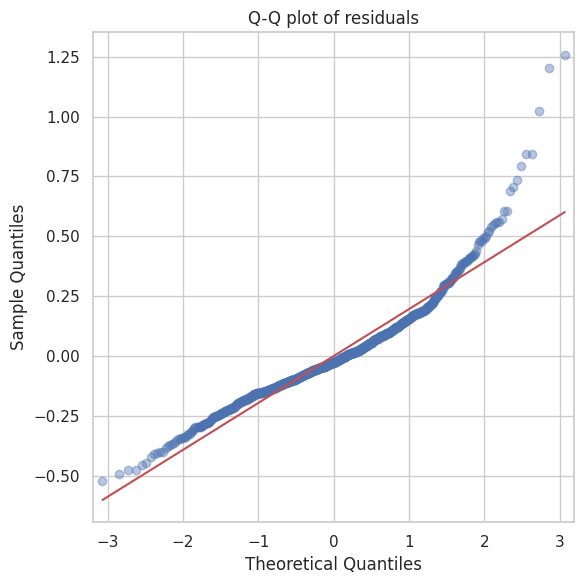

Residual skewness 1.38 (0 = symmetric), excess kurtosis 5.27 (0 = normal tails)


In [10]:
fig, ax = plt.subplots(figsize=(6, 6))
sm.qqplot(resid, line="s", ax=ax, alpha=0.4)
ax.set_title("Q-Q plot of residuals")
save_fig("10_qq_plot")
print(f"Residual skewness {resid.skew():.2f} (0 = symmetric), excess kurtosis {resid.kurt():.2f} (0 = normal tails)")

**Verdict: roughly holds in the middle, not in the right tail.** Points follow the diagonal for most of the range, then bend
upwards at the top: there are more very bad years than a normal distribution expects. That is what large claims do,
since they are occasional, big, and only push one way.

**What it means:** with about 930 training rows, the coefficient estimates and their confidence intervals are still
reasonable (the central limit theorem covers mild non-normality at this size). The model will, however, **understate how
bad a bad year can be**, so it should not be used to set tail-risk capital.

### Check 3 · Variance inflation factor (multicollinearity)

In [11]:
X = pd.DataFrame(model.model.exog, columns=model.model.exog_names)
vif = pd.DataFrame({
    "VIF": [variance_inflation_factor(X.values, i) for i in range(X.shape[1])],
}, index=X.columns.map(short)).drop(index="Intercept").sort_values("VIF", ascending=False)
vif

,VIF
Region: VIC,1.5763
Region: WA,1.5585
Region: QLD,1.5496
Region: SA,1.4429
Line: TPD,1.4341
Line: Income Protection,1.4032
Line: Trauma,1.3850
Type: Excess of Loss,1.2177
Type: Surplus,1.1817
log_policies,1.1627


**Verdict: holds.** Every VIF is below 2, far under the warning level of 5. Each predictor carries its own information,
so the coefficients can be read one at a time. This is the payoff from the choice in notebook 01 to use a single size
measure: putting premium, claim count and policies in force in together would have pushed VIF well past 5.

### Check 4 · Influence (Cook's distance)

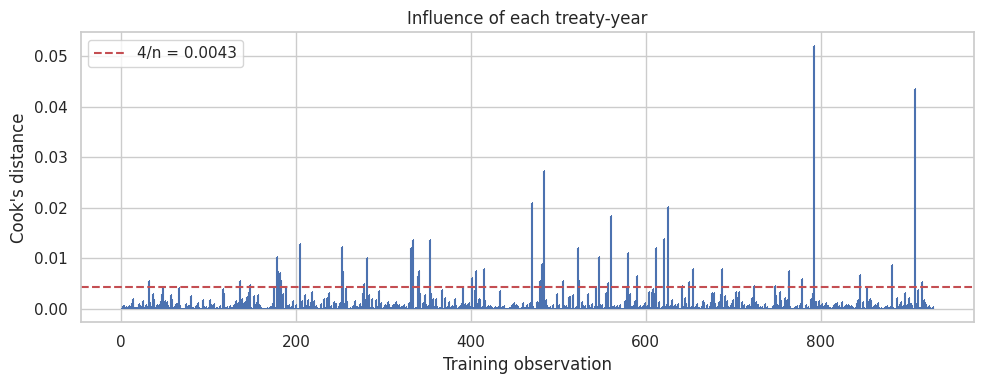

50 of 930 treaty-years above 4/n; largest Cook's distance 0.052


,treaty_id,year,line_of_business,large_claim_count,policies_in_force,loss_ratio,cooks
317,TR0039,2021,Trauma,0,1805,1.9524,0.0521
747,TR0100,2021,Income Protection,0,710,1.9833,0.0435
188,TR0025,2020,Trauma,0,735,1.7733,0.0273
746,TR0099,2025,Death,1,579,1.5795,0.0210
364,TR0045,2022,Income Protection,0,1097,1.5396,0.0202


In [12]:
influence = model.get_influence()
cooks = influence.cooks_distance[0]
threshold = 4 / len(train)

fig, ax = plt.subplots(figsize=(10, 4))
ax.stem(np.arange(len(cooks)), cooks, markerfmt=",", basefmt=" ")
ax.axhline(threshold, color="#C44E52", linestyle="--", label=f"4/n = {threshold:.4f}")
ax.set(xlabel="Training observation", ylabel="Cook's distance", title="Influence of each treaty-year")
ax.legend()
save_fig("11_cooks_distance")

influential = train.assign(cooks=cooks).sort_values("cooks", ascending=False)
print(f"{(cooks > threshold).sum()} of {len(train)} treaty-years above 4/n; largest Cook's distance {cooks.max():.3f}")
influential[["treaty_id", "year", "line_of_business", "large_claim_count", "policies_in_force", "loss_ratio", "cooks"]].head()

In [13]:
# Do the conclusions survive without the influential points?
trimmed = smf.ols(formula, data=train[cooks <= threshold]).fit()
stability = pd.DataFrame({"all data": model.params, "without influential": trimmed.params}).drop(index="Intercept")
stability.index = stability.index.map(short)
stability.loc[["Line: Income Protection", "Line: Trauma", "Line: TPD", "treaty_age", "large_claim_count", "cession_pct"]]

,all data,without influential
Line: Income Protection,0.2631,0.2571
Line: Trauma,0.1742,0.1540
Line: TPD,0.1061,0.0785
treaty_age,0.0170,0.0196
large_claim_count,0.1274,0.1211
cession_pct,-0.0060,-0.0373


**Verdict: holds.** No single treaty-year comes close to a Cook's distance of 1 (the usual "this one point changes the
model" level); the largest is about 0.05. The 50 points above the stricter 4/n line are mostly **small treaties with an
unusually bad year**, exactly where the funnel in Check 1 predicted the biggest residuals. Refitting without them, every
effect keeps its direction and the ordering Income Protection > Trauma > TPD holds. TPD moves most (0.11 to 0.08), so
its size is the least certain of the line-of-business effects; the headline findings are not driven by a handful of rows.

### One more honest limitation

Loss ratio cannot go below zero, but OLS treats it as unbounded. With a mean around 0.76 and few values near zero this
does little harm here, but a model like gamma regression (with a log link) would respect the bound and suit the right
skew. That is a sensible next step rather than a reason to distrust these results.

## Conclusion

- The regression **beats the baseline**: test RMSE falls from about 0.23 to 0.19, roughly a **17% improvement**, and it
  explains about **30%** of the variation in loss ratio on unseen data. The rest is year-to-year noise, mostly large claims
  and small-treaty volatility, which no annual model can predict.
- **Line of business is the dominant driver**: Income Protection runs about 0.26 worse than Death, Trauma 0.17, TPD 0.11.
- **Age (+0.017 a year) and large claims (+0.13 each)** add on top. Treaty type matters a little; size, cession and region
  do not move the average.
- The assumption checks expose non-constant variance and a heavy right tail; robust standard errors confirm that none of
  the conclusions change.

Notebook 03 turns this into a list of treaties to act on.

## Export for the dashboard

The dashboard's **Check a treaty** tab lets someone type in a treaty and see its expected loss ratio and *why*. Rather than
saving the fitted model as a pickle file (which breaks easily when deployed), the coefficients are written to a small CSV
and the app does the arithmetic itself: expected loss ratio = intercept + the sum of each feature's coefficient × its value.

The training residuals are saved too. Adding them to an expected loss ratio shows how often a treaty like this one ends
up above 1.0, which gives a **chance of losing money**. Residuals are matched by treaty size, because small treaties
swing far more than large ones.

In [14]:
import json
import re

def tidy(term):
    """Split a statsmodels term name into (feature, level)."""
    if term == "Intercept":
        return "intercept", ""
    m = re.match(r"C\((\w+), Treatment\('[^']*'\)\)\[T\.(.+)\]", term)
    return (m.group(1), m.group(2)) if m else (term, "")

ci = model.conf_int()
coefficients = pd.DataFrame([
    {"feature": tidy(t)[0], "level": tidy(t)[1], "coefficient": model.params[t],
     "ci_low": ci.loc[t, 0], "ci_high": ci.loc[t, 1], "p_value": model.pvalues[t]}
    for t in model.params.index
])
coefficients.to_csv(ROOT / "outputs" / "model_coefficients.csv", index=False)

# Training residuals with treaty size: used to turn an expected loss ratio into a CHANCE of losing money.
# Residuals are kept by size band because small treaties swing much more (the funnel in Check 1).
size_edges = np.quantile(train.policies_in_force, [0, 0.2, 0.4, 0.6, 0.8, 1.0])
pd.DataFrame({"residual": model.resid.round(5), "policies_in_force": train.policies_in_force}) \
  .to_csv(ROOT / "outputs" / "model_residuals.csv", index=False)

summary = {"test_rmse": float(model_rmse), "baseline_rmse": float(baseline_rmse), "test_r2": float(model_r2),
           "train_rows": int(model.nobs), "size_band_edges": [float(x) for x in size_edges],
           "reference_levels": {"line_of_business": "Death", "treaty_type": "Quota Share", "region": "NSW"}}
(ROOT / "outputs" / "model_summary.json").write_text(json.dumps(summary, indent=2))
print("Wrote outputs/model_coefficients.csv, model_summary.json and model_residuals.csv")
coefficients

Wrote outputs/model_coefficients.csv, model_summary.json and model_residuals.csv


,feature,level,coefficient,ci_low,ci_high,p_value
0,intercept,,0.4274,0.3198,0.5350,0.0000
1,line_of_business,Income Protection,0.2631,0.2280,0.2982,0.0000
2,line_of_business,TPD,0.1061,0.0673,0.1449,0.0000
3,line_of_business,Trauma,0.1742,0.1394,0.2091,0.0000
4,treaty_type,Excess of Loss,0.0681,0.0319,0.1044,0.0002
5,treaty_type,Surplus,0.0540,0.0240,0.0840,0.0004
6,region,QLD,0.0059,-0.0361,0.0479,0.7812
7,region,SA,0.0098,-0.0318,0.0514,0.6437
8,region,VIC,-0.0113,-0.0500,0.0273,0.5655
9,region,WA,0.0153,-0.0232,0.0537,0.4353
